# EDA статей Cointelegraph

Посмотрим, какие статьи собраны в `data/articles.csv`: за какой период, о чём они
и насколько отличаются по длине. Отдельно рассмотрим пометки BTC и ETH.

Выбери Python из `.venv` и выполни ячейки сверху вниз. Рабочая папка —
`cointelegraph_parser`; зависимости указаны в `requirements-eda.txt`.
Все даты в анализе — UTC. CSV только читаем.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 110})
pd.set_option("display.max_colwidth", 90)

## 1. Загрузка данных

Одна строка — одна сохранённая статья. `published_at` — дата публикации,
`first_seen_at` — первое сохранение парсером. Теги и пометки валют хранятся
как JSON-списки: преобразуем их в обычные списки Python.

In [2]:
df = pd.read_csv("data/articles.csv")
print(f"В файле {len(df):,} строк и {df.shape[1]} столбцов")
display(df.head())

В файле 45,682 строк и 9 столбцов


,id,language,url,title,text,published_at,tags,symbols,first_seen_at
0,50c4153db9f735c5d652ca7bc6ac16f1f5538510801cf6db36b96d8e3218e828,en,https://cointelegraph.com/news/us-officials-to-investigate-digital-currencies-oversight,US officials to investigate digital currencies’ oversight,The New York Times reports that American officials at the state and federal levels are...,2013-08-14T15:10:00+00:00,"[""Digital Currency"", ""United States"", ""Bitcoin""]","[""BTC""]",2026-10-16T11:32:01.676196+00:00
1,4017aa3f24942f69fb6771ce8488db85b2e84a1a5f464b81e741f6847c409cb4,en,https://cointelegraph.com/news/android-vulnerability-to-blame-for-5-720-bitcoin-theft,"Android vulnerability to blame for $5,720 Bitcoin theft","The flaw has wide-reaching potential effects, one of which was proved last week when a...",2013-08-15T12:20:00+00:00,"[""Android"", ""Cryptography"", ""Bitcoin""]","[""BTC""]",2026-10-16T11:32:06.643031+00:00
2,b27643a572ad41ecf3fcd0d96d0625608b7f479bd731cb306610df54f25ef049,en,https://cointelegraph.com/news/germany-is-first-to-offer-official-opinion-on-bitcoin,Germany is first to offer official opinion on Bitcoin,Germany’s Ministry of Finance is on record acknowledging the digital currency as “priv...,2013-08-20T10:15:00+00:00,"[""Germany"", ""Bitcoin""]","[""BTC""]",2026-10-16T11:32:11.858136+00:00
3,318b1010901cd4ce54a6fd242a0e852f585418d09cee0d93f66df54c63c42e87,en,https://cointelegraph.com/news/mr-satoshi-goes-to-washington,Mr. Satoshi goes to Washington,FinCEN has called a meeting with a few federal agents to discuss Bitcoin and consider ...,2013-08-20T13:10:00+00:00,"[""Washington"", ""FinCEN"", ""Bitcoin Regulation"", ""Bitcoin""]","[""BTC""]",2026-10-16T11:32:16.728183+00:00
4,be230d81c909a4a5142eb8d58d69f85eb50988e349b0a86750922a0dcb900a07,en,https://cointelegraph.com/news/trsst-secure-blogging-messaging-platform-for-the-open-web,"Trsst: Secure blogging, messaging platform for the open web","Proponents of online anonymity, or at least the access to it, might have high praise f...",2013-08-21T10:20:00+00:00,"[""Messaging App"", ""Micropayments"", ""Bitcoin""]","[""BTC""]",2026-10-16T11:32:21.805734+00:00


In [3]:
for column in ["published_at", "first_seen_at"]:
    df[column] = pd.to_datetime(df[column], format="ISO8601", utc=True)

for column in ["tags", "symbols"]:
    df[column] = df[column].map(json.loads)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45682 entries, 0 to 45681
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   id             45682 non-null  object             
 1   language       45682 non-null  object             
 2   url            45682 non-null  object             
 3   title          45682 non-null  object             
 4   text           45682 non-null  object             
 5   published_at   45682 non-null  datetime64[ns, UTC]
 6   tags           45682 non-null  object             
 7   symbols        45682 non-null  object             
 8   first_seen_at  45682 non-null  datetime64[ns, UTC]
dtypes: datetime64[ns, UTC](2), object(7)
memory usage: 3.1+ MB


In [4]:
df = df[df["published_at"].dt.year > 2013]

## 2. Пропуски и повторы

Для начала посмотрим на пропуски и повторяющиеся URL, заголовки и тексты.
У заголовков и текстов перед сравнением уберём различия в регистре и пробелах.
В таблице повторов считаются все строки группы, включая первую.
Пустой список тегов или валют — отдельный случай, а не пропуск.

In [5]:
missing = df.isna().sum().to_frame("Пропусков")
missing["Доля, %"] = (missing["Пропусков"] / len(df) * 100).round(1)
display(missing)

titles = df["title"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
texts = df["text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
duplicates = pd.Series({
    "Одинаковые URL": df["url"].duplicated(keep=False).sum(),
    "Одинаковые заголовки": titles.duplicated(keep=False).sum(),
    "Одинаковые тексты": texts.duplicated(keep=False).sum(),
})
display(duplicates.to_frame("Строк в группах повторов"))
display(df.loc[texts.duplicated(keep=False), ["title", "url"]].head(10))

,Пропусков,"Доля, %"
id,0,0.0
language,0,0.0
url,0,0.0
title,0,0.0
text,0,0.0
published_at,0,0.0
tags,0,0.0
symbols,0,0.0
first_seen_at,0,0.0


,Строк в группах повторов
Одинаковые URL,0
Одинаковые заголовки,25
Одинаковые тексты,6


,title,url
3772,Ethereum may decline 10% versus Bitcoin despite record ETH staking,https://cointelegraph.com/markets/ethereum-may-decline-10-versus-bitcoin-despite-recor...
3773,Ethereum risks 10% decline versus Bitcoin despite record ETH staking,https://cointelegraph.com/markets/ethereum-decline-10percent-versus-bitcoin-despite-re...
3788,"Phishing, deepfakes, supply chain attacks to fuel 2026's biggest crypto hacks: CertiK",https://cointelegraph.com/news/crypto-hacks-2026-certik-blockchain-investigator-attack...
3790,"Phishing, deepfakes, supply chain attacks to fuel 2026's biggest crypto hacks: CertiK",https://cointelegraph.com/news/phishing-deepfakes-supply-chain-attacks-to-fuel-2026-s-...
3848,"Price predictions 4/24: BTC, ETH, XRP, BNB, SOL, DOGE, HYPE, ADA, BCH, XMR",https://cointelegraph.com/markets/price-predictions-424-btc-eth-xrp-bnb-sol-doge-hype-...
3850,"Price predictions 4/24: BTC, ETH, XRP, BNB, SOL, DOGE, HYPE, ADA, BCH, XMR",https://cointelegraph.com/markets/price-predictions-4-24-btc-eth-xrp-bnb-sol-doge-hype...


## 3. Период и выборка

Для анализа берём весь архив CSV. Статьи считаем по уникальным URL.

In [6]:
articles = df.drop_duplicates("url").copy()
articles["section"] = articles["url"].str.split("/").str[3]
articles["word_count"] = articles["text"].str.split().str.len()
articles["char_count"] = articles["text"].str.len()
articles["tag_count"] = articles["tags"].map(set).map(len)
articles["collection_lag_days"] = (
    articles["first_seen_at"] - articles["published_at"]
).dt.total_seconds() / 86400

earliest = articles["published_at"].min()
latest = articles["published_at"].max()

print(f"Уникальных статей: {len(articles):,}")
print(f"Повторных строк по URL исключено: {len(df) - len(articles)}")
print(f"Весь архив: {earliest:%d.%m.%Y} — {latest:%d.%m.%Y}")
display(articles["language"].value_counts().to_frame("Статей"))

Уникальных статей: 45,670
Повторных строк по URL исключено: 0
Весь архив: 01.11.2021 — 31.10.2026


,Статей
language,
en,45670


### Как распределены публикации по времени

Ноль на дневном графике означает отсутствие записей в CSV. По нему нельзя
утверждать, что в этот день на сайте не было новостей. Последние месяц и день
могут быть собраны не полностью. На месячном графике показаны только месяцы с записями.

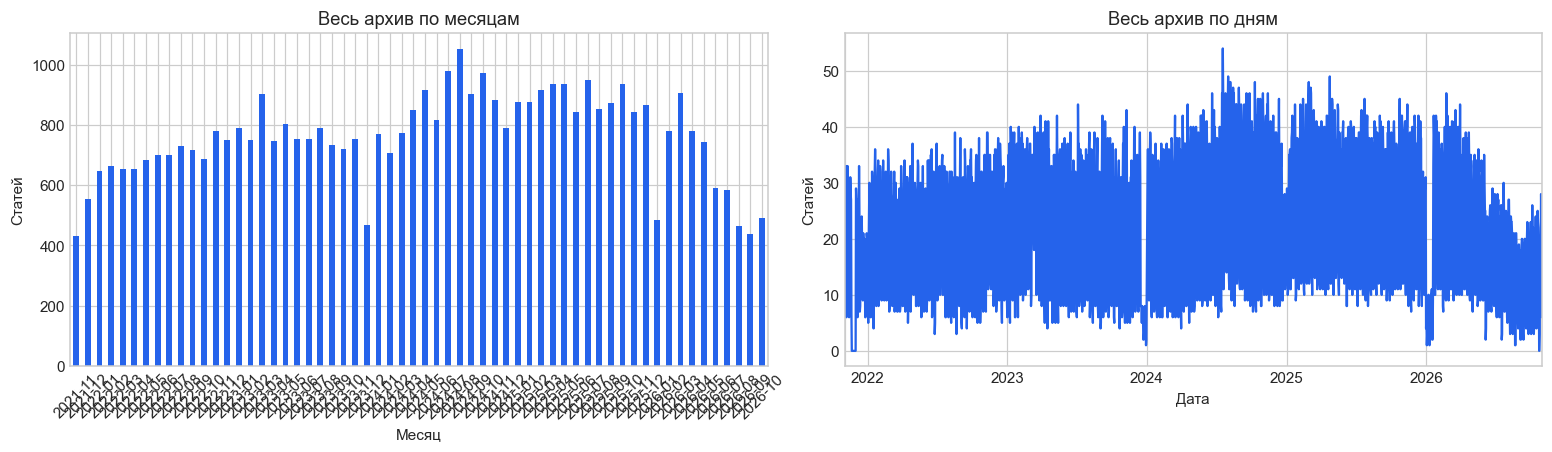

В среднем за день за весь период: 25.0 статей
Дней без записей: 12


In [7]:
monthly = articles.groupby(articles["published_at"].dt.strftime("%Y-%m")).size()
daily = articles.set_index("published_at").resample("D").size()
days = pd.date_range(earliest.normalize(), latest.normalize(), freq="D")
daily = daily.reindex(days, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
monthly.plot.bar(ax=axes[0], color="#2563eb", rot=45)
axes[0].set(title="Весь архив по месяцам", xlabel="Месяц", ylabel="Статей")
daily.plot(ax=axes[1], color="#2563eb")
axes[1].set(title="Весь архив по дням", xlabel="Дата", ylabel="Статей")
plt.show()

print(f"В среднем за день за весь период: {daily.mean():.1f} статей")
print(f"Дней без записей: {daily.eq(0).sum()}")

## 4. Разделы сайта

Раздел берём из URL: например, `/news/...` соответствует `news`.
Это структура сайта, а темы статей посмотрим по тегам ниже.

,Статей,"Доля, %"
section,,
news,33988,74.4
markets,7539,16.5
magazine,2590,5.7
opinion,1076,2.4
interview,357,0.8
features,102,0.2
research,8,0.0
ecosystem,7,0.0
multimedia,3,0.0


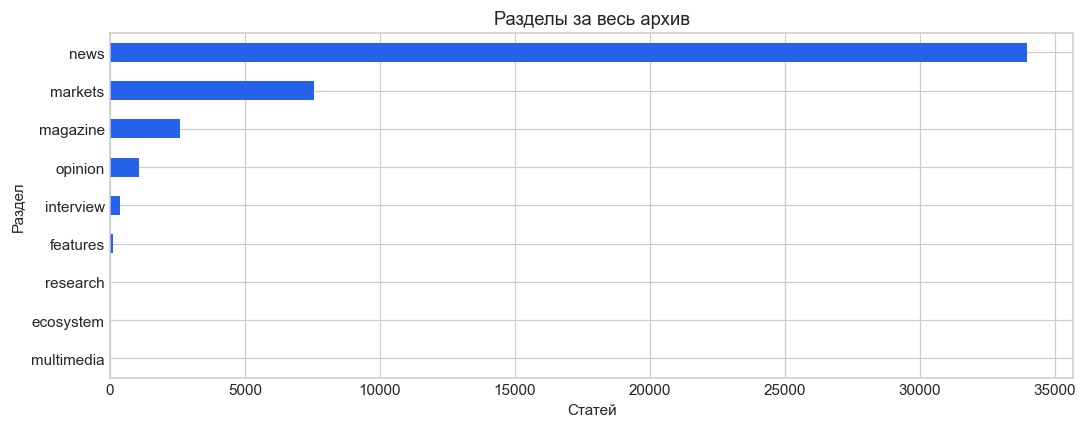

In [8]:
sections = articles["section"].value_counts().to_frame("Статей")
sections["Доля, %"] = (sections["Статей"] / len(articles) * 100).round(1)
display(sections)

sections["Статей"].sort_values().plot.barh(color="#2563eb")
plt.title("Разделы за весь архив")
plt.xlabel("Статей")
plt.ylabel("Раздел")
plt.tight_layout()
plt.show()

## 5. Длина текстов

Длину в словах считаем разделением по пробелам. Посмотрим на распределение
и различия между разделами. Статьи короче 150 слов выведем отдельно:
их удобно просмотреть вручную, но сама длина не говорит об обрезке текста.

,word_count,char_count,tag_count
count,45670.0,45670.0,45670.0
mean,549.4,3498.4,6.3
std,330.7,2033.8,2.8
min,84.0,572.0,1.0
25%,377.0,2428.0,5.0
50%,446.0,2867.0,6.0
75%,565.0,3615.0,7.0
max,10269.0,64220.0,34.0


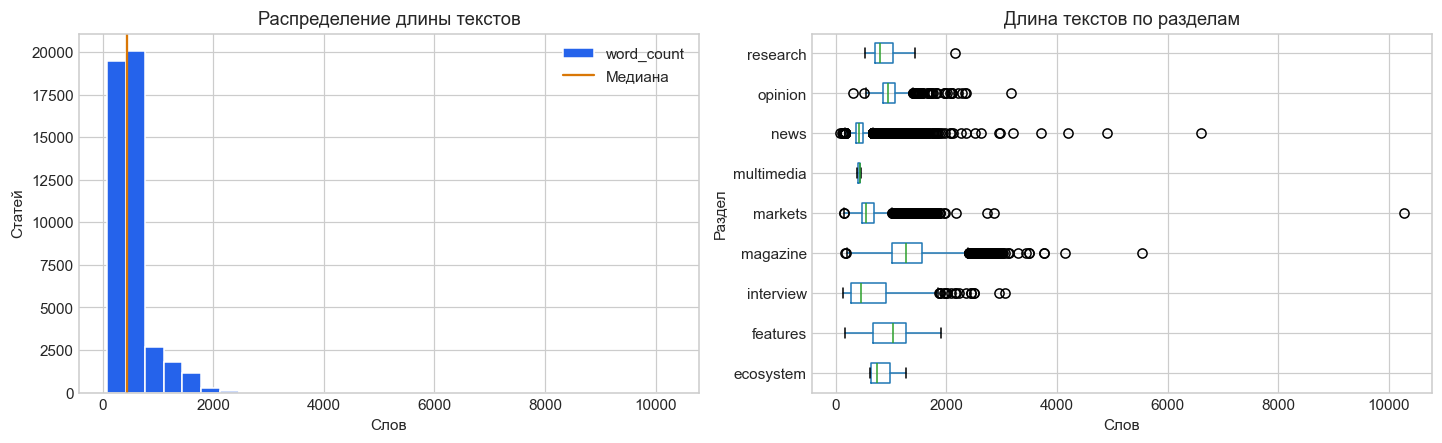

In [9]:
display(articles[["word_count", "char_count", "tag_count"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
articles["word_count"].plot.hist(bins=30, ax=axes[0], color="#2563eb", edgecolor="white")
axes[0].axvline(articles["word_count"].median(), color="#d97706", label="Медиана")
axes[0].set(title="Распределение длины текстов", xlabel="Слов", ylabel="Статей")
axes[0].legend()
articles.boxplot(column="word_count", by="section", ax=axes[1], vert=False)
axes[1].set(title="Длина текстов по разделам", xlabel="Слов", ylabel="Раздел")
fig.suptitle("")
plt.show()

In [10]:
short = articles.loc[articles["word_count"] < 150].sort_values("word_count")
print(f"Короче 150 слов: {len(short)} статей ({len(short) / len(articles):.1%})")
display(short[["title", "word_count", "url"]].head(10))

print("Самые длинные статьи:")
display(articles.nlargest(3, "word_count")[["title", "section", "word_count", "url"]])

Короче 150 слов: 25 статей (0.1%)


,title,word_count,url
103,"Swiss stablecoin sandbox enters testing phase, adds two new partners",84,https://cointelegraph.com/news/swiss-stablecoin-sandbox-testing-phase-two-new-partners
22327,Ethereum Foundation wallet moves 92K ETH after 7 years,109,https://cointelegraph.com/news/ethereum-foundation-wallet-moved-ether
673,VanEck seeks to withdraw application for Lido staked Ether ETF,124,https://cointelegraph.com/news/vaneck-seeks-to-withdraw-application-for-lido-staked-et...
260,Cardano’s IOG warns users to avoid YouTube channel amid apparent hijack,128,https://cointelegraph.com/news/cardanos-iog-warns-users-to-avoid-youtube-channel-amid-...
450,CFTC seeks to define event contracts as swaps amid prediction market fight,129,https://cointelegraph.com/news/cftc-seeks-to-define-event-contracts-as-swaps-amid-pred...
201,Democrats push back on GOP’s ‘final’ CLARITY offer with counterproposal: Politico,137,https://cointelegraph.com/news/democrats-push-back-on-gops-final-clarity-offer-with-co...
40228,"Despite ‘worst bear market ever,’ Bitcoin has become more resilient, Glassnode analyst...",137,https://cointelegraph.com/interview/despite-worst-bear-market-ever-bitcoin-has-become-...
1652,London Stock Exchange eyes overnight trading launch in 2027: FT,137,https://cointelegraph.com/news/london-stock-exchange-plans-round-the-clock-trading-in-...
1573,Hyperion DeFi to deploy 500K HYPE for Hyperliquid HIP-3 markets,140,https://cointelegraph.com/news/hyperion-defi-to-deploy-500k-hype-for-hyperliquid-hip-3...
1819,Trump teleprompter operator accused over Kalshi bets leaves government: AP,140,https://cointelegraph.com/news/trump-teleprompter-kalshi-bets-government-ap


Самые длинные статьи:


,title,section,word_count,url
14011,Bitcoin traders warn BTC price rally may stall at $90K,markets,10269,https://cointelegraph.com/markets/bitcoin-traders-warn-btc-price-may-stall-90k
27902,Sam Bankman-Fried trial [Day 17] — latest update: Live coverage,news,6597,https://cointelegraph.com/news/sam-bankman-fried-ftx-trial-updates
13799,Best crypto exchanges of 2025,magazine,5539,https://cointelegraph.com/magazine/best-crypto-exchanges-of-2025


## 6. Популярные теги

Считаем число статей с каждым тегом. Повтор одного тега внутри статьи учитываем
один раз. У статьи может быть несколько тегов, поэтому сумма долей превышает 100%.

Уникальных тегов: 1301
Статей без тегов: 0


,Статей,"Доля, %"
tag,,
Bitcoin,23284,51.0
Cryptocurrencies,13137,28.8
Business,13131,28.8
Adoption,10117,22.2
Blockchain,8648,18.9
Markets,8183,17.9
Bitcoin Price,7961,17.4
Regulation,6319,13.8
United States,5998,13.1


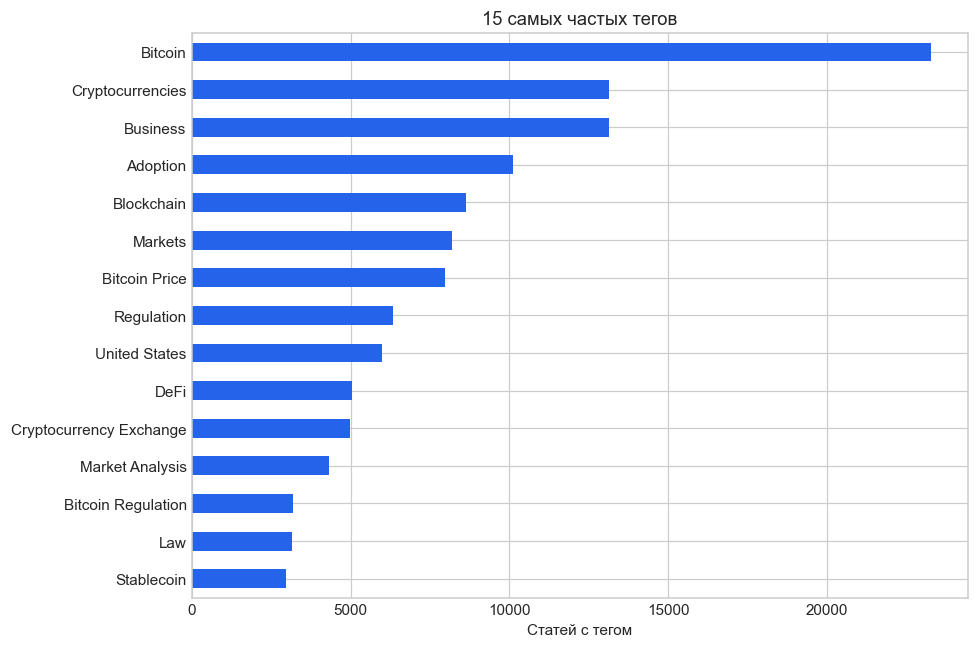

In [11]:
article_tags = articles["tags"].explode().dropna().rename("tag").reset_index()
article_tags = article_tags.drop_duplicates(["index", "tag"])
tags = article_tags["tag"].value_counts().to_frame("Статей")
tags["Доля, %"] = (tags["Статей"] / len(articles) * 100).round(1)

print(f"Уникальных тегов: {len(tags)}")
print(f"Статей без тегов: {articles['tags'].map(len).eq(0).sum()}")
display(tags.head(20))

tags["Статей"].head(15).sort_values().plot.barh(figsize=(9, 6), color="#2563eb")
plt.title("15 самых частых тегов")
plt.xlabel("Статей с тегом")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 7. Пометки BTC и ETH

`symbols` — пометки парсера по заголовку, тексту и тегам. Разделим статьи на
четыре группы без пересечений. Пустой список означает, что парсер не поставил
ни одну из пометок; это не гарантирует отсутствие упоминаний в статье.

,Статей,"Доля, %"
symbol_group,,
Только BTC,21120,46.2
Только ETH,4266,9.3
BTC и ETH,11507,25.2
Без BTC/ETH,8777,19.2


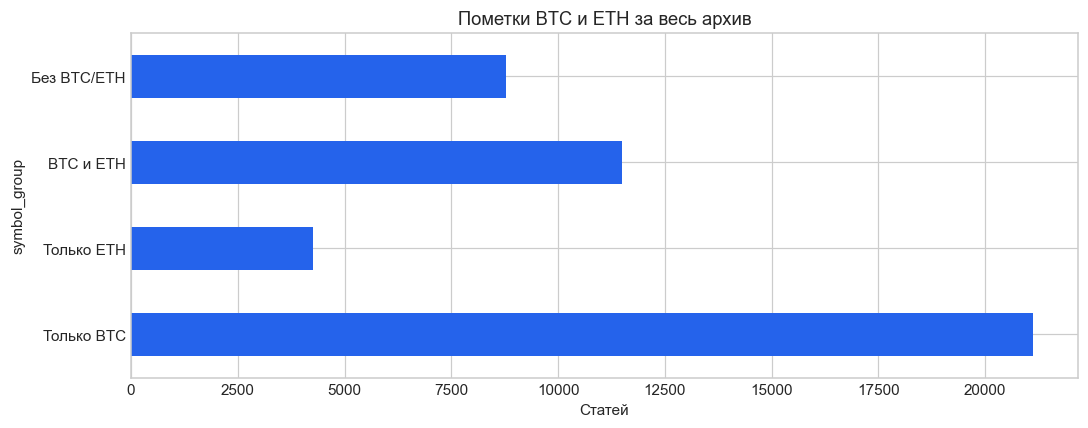

С учётом совместных упоминаний: BTC — 32627, ETH — 15773 статей


In [12]:
has_btc = articles["symbols"].map(lambda symbols: "BTC" in symbols)
has_eth = articles["symbols"].map(lambda symbols: "ETH" in symbols)
articles["symbol_group"] = "Без BTC/ETH"
articles.loc[has_btc & ~has_eth, "symbol_group"] = "Только BTC"
articles.loc[has_eth & ~has_btc, "symbol_group"] = "Только ETH"
articles.loc[has_btc & has_eth, "symbol_group"] = "BTC и ETH"

group_order = ["Только BTC", "Только ETH", "BTC и ETH", "Без BTC/ETH"]
symbol_counts = (
    articles["symbol_group"].value_counts()
    .reindex(group_order, fill_value=0).to_frame("Статей")
)
symbol_counts["Доля, %"] = (symbol_counts["Статей"] / len(articles) * 100).round(1)
display(symbol_counts)

symbol_counts["Статей"].plot.barh(color="#2563eb")
plt.title("Пометки BTC и ETH за весь архив")
plt.xlabel("Статей")
plt.tight_layout()
plt.show()

btc_count = has_btc.sum()
eth_count = has_eth.sum()
print(f"С учётом совместных упоминаний: BTC — {btc_count}, ETH — {eth_count} статей")

## 8. Какие теги встречаются вместе

Для восьми самых частых тегов посчитаем совместные появления в статьях.
На диагонали — число статей с самим тегом. Матрица показывает частоты, а не корреляции.

tag,Bitcoin,Cryptocurrencies,Business,Adoption,Blockchain,Markets,Bitcoin Price,Regulation
tag,,,,,,,,
Bitcoin,23284,7067,7389,5477,0,6161,7637,0
Cryptocurrencies,7067,13137,3500,3520,2739,3923,3425,1232
Business,7389,3500,13131,4011,3054,331,954,1262
Adoption,5477,3520,4011,10117,2874,444,1150,736
Blockchain,0,2739,3054,2874,8648,189,35,0
Markets,6161,3923,331,444,189,8183,5657,25
Bitcoin Price,7637,3425,954,1150,35,5657,7961,18
Regulation,0,1232,1262,736,0,25,18,6319


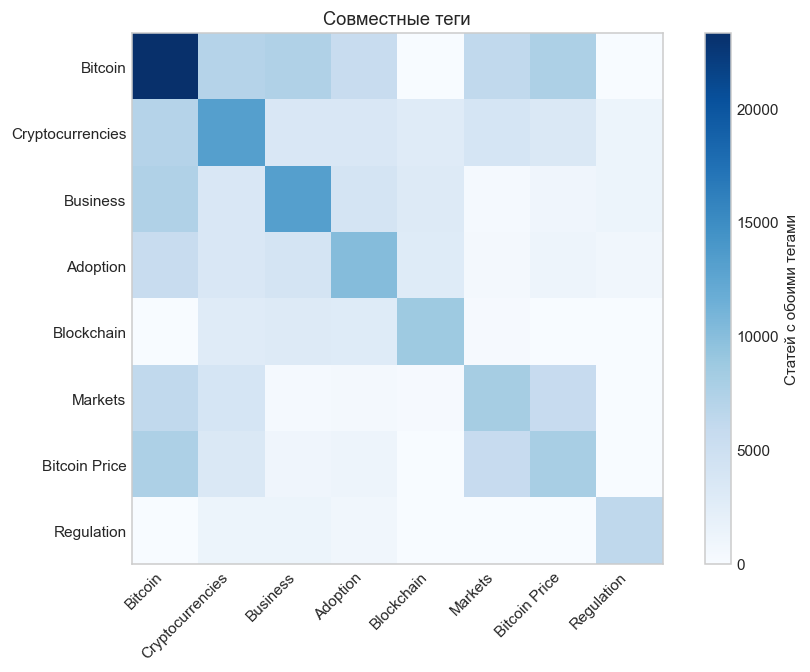

In [13]:
top_tags = tags.head(8).index
top_article_tags = article_tags.loc[article_tags["tag"].isin(top_tags)]
tag_matrix = pd.crosstab(top_article_tags["index"], top_article_tags["tag"])[top_tags]
cooccurrence = tag_matrix.T @ tag_matrix
display(cooccurrence)

fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
image = ax.imshow(cooccurrence, cmap="Blues")
ax.set_xticks(range(len(top_tags)), top_tags, rotation=45, ha="right")
ax.set_yticks(range(len(top_tags)), top_tags)
ax.set_title("Совместные теги")
ax.grid(False)
fig.colorbar(image, ax=ax, label="Статей с обоими тегами")
plt.show()

## 9. Когда собирались статьи

Сгруппируем статьи по дню первого сохранения. Разница между публикацией и
сохранением включает загрузку архива, поэтому не характеризует скорость мониторинга.

In [14]:
collection = articles.groupby(articles["first_seen_at"].dt.date).agg(
    articles=("url", "size"),
    first_saved=("first_seen_at", "min"),
    last_saved=("first_seen_at", "max"),
)
display(collection.rename(columns={
    "articles": "Статей", "first_saved": "Начало сбора", "last_saved": "Конец сбора"
}))
display(articles["collection_lag_days"].describe().round(1).to_frame("Дней до сохранения"))

,Статей,Начало сбора,Конец сбора
first_seen_at,,,
2026-10-18,708,2026-10-18 20:20:17.414343+00:00,2026-10-18 21:24:29.765604+00:00
2026-10-24,1525,2026-10-24 21:50:07.813247+00:00,2026-10-24 23:59:59.667782+00:00
2026-10-25,3979,2026-10-25 00:00:04.498742+00:00,2026-10-25 18:31:09.761577+00:00
2026-10-31,1443,2026-10-31 11:49:02.746678+00:00,2026-10-31 12:39:18.061851+00:00
2026-11-03,38015,2026-11-03 11:12:02.752511+00:00,2026-11-03 23:34:34.345808+00:00


,Дней до сохранения
count,45670.0
mean,899.5
std,499.1
min,0.0
25%,485.2
50%,866.3
75%,1325.0
max,1828.8


## 10. Что получилось

Краткая сводка обновляется при выполнении ноутбука. Она описывает собранную
выборку; полноту архива сайта по одному CSV оценить нельзя.

In [15]:
display(Markdown(f"""
- В архиве **{len(articles):,} уникальных статей**.
- Самый частый раздел — **{sections.index[0]}** ({sections.iloc[0]['Доля, %']:.1f}%).
- Самый частый тег — **{tags.index[0]}** ({tags.iloc[0]['Статей']:.0f} статей).
- Медианная длина текста — **{articles['word_count'].median():.0f} слов**;
  короче 150 слов — **{len(short)} статей**.
- Пометка BTC есть у **{btc_count} статей**, ETH — у **{eth_count}**.
  Статьи с обеими пометками входят в оба числа.

Короткие тексты и совпадения стоит просмотреть по ссылкам. Для дальнейшего
анализа динамики нужно учитывать неравномерность сбора и неполный последний месяц.
"""))


- В архиве **45,670 уникальных статей**.
- Самый частый раздел — **news** (74.4%).
- Самый частый тег — **Bitcoin** (23284 статей).
- Медианная длина текста — **446 слов**;
  короче 150 слов — **25 статей**.
- Пометка BTC есть у **32627 статей**, ETH — у **15773**.
  Статьи с обеими пометками входят в оба числа.

Короткие тексты и совпадения стоит просмотреть по ссылкам. Для дальнейшего
анализа динамики нужно учитывать неравномерность сбора и неполный последний месяц.
